## CL-1 Lab Assignment 5 (Group B): Data Aggregation
### Analyzing Sales Performance by Region in a Retail Company

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

In [2]:
FILE = "Retail_Sales_Data.csv"

try:
    df = pd.read_csv(FILE)
except FileNotFoundError:
    print("Retail_Sales_Data.csv was not found!")
else:
    print(f"Loaded {FILE}")

display(df.head())

Loaded Retail_Sales_Data.csv


,Transaction_Date,Region,Product_Category,Quantity,Sales_Amount
0,2025-01-09,South,Grocery,1,2439.78
1,2025-03-11,West,Furniture,1,3831.02
2,2025-02-28,North,Grocery,2,4526.31
3,2025-02-09,West,Electronics,8,3631.41
4,2025-02-08,East,Furniture,5,4819.73


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))
print("\nSummary statistics:")
display(df.describe(include="all").T)

Shape: (300, 5)

Columns:
['Transaction_Date', 'Region', 'Product_Category', 'Quantity', 'Sales_Amount']

Data types:


,dtype
Transaction_Date,object
Region,object
Product_Category,object
Quantity,int64
Sales_Amount,float64



Missing values:


,missing
Transaction_Date,0
Region,0
Product_Category,0
Quantity,0
Sales_Amount,0



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction_Date,300,87,2025-03-12,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,300,4,West,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,300,4,Grocery,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,300.0,NaN,NaN,NaN,5.02,2.441202,1.0,3.0,5.0,7.0,9.0
Sales_Amount,300.0,NaN,NaN,NaN,2536.277933,1461.812002,106.04,1278.1725,2560.31,3798.195,4993.84


In [4]:
# Identify relevant variables using common column names.
def find_col(columns, keywords):
    for c in columns:
        x = c.lower().replace(" ", "_")
        if any(k in x for k in keywords):
            return c
    return None

region_col = find_col(df.columns, ["region"])
sales_col = find_col(df.columns, ["sales_amount", "sales", "amount", "revenue"])
category_col = find_col(df.columns, ["product_category", "category", "product"])

print("Region column:", region_col)
print("Sales amount column:", sales_col)
print("Product category column:", category_col)

if sales_col:
    df[sales_col] = pd.to_numeric(df[sales_col], errors="coerce")

Region column: Region
Sales amount column: Sales_Amount
Product category column: Product_Category


,Total Sales
Region,
North,229750.53
West,202726.49
South,165114.59
East,163291.77


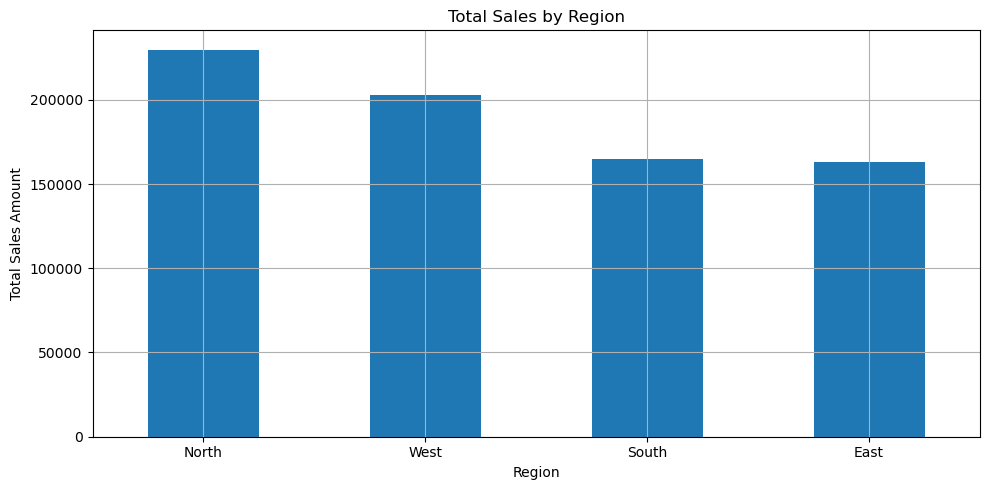

In [5]:
if region_col and sales_col:
    region_sales = df.groupby(region_col)[sales_col].sum().sort_values(ascending=False)
    display(region_sales.to_frame("Total Sales"))

    plt.figure()
    region_sales.plot(kind="bar")
    plt.title("Total Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Total Sales Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns were not identified.")

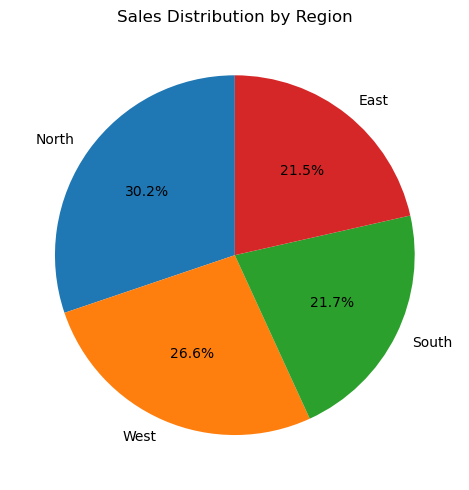

In [6]:
if region_col and sales_col:
    region_sales = df.groupby(region_col)[sales_col].sum().sort_values(ascending=False)
    plt.figure()
    region_sales.plot(kind="pie", autopct="%1.1f%%", startangle=90)
    plt.title("Sales Distribution by Region")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

In [7]:
if region_col and sales_col:
    region_sales = df.groupby(region_col)[sales_col].sum().sort_values(ascending=False)
    top_regions = region_sales.head()
    print("Top-performing regions based on total sales:")
    display(top_regions.to_frame("Total Sales"))

    if len(region_sales):
        print(f"Highest-sales region: {region_sales.index[0]}")

Top-performing regions based on total sales:


,Total Sales
Region,
North,229750.53
West,202726.49
South,165114.59
East,163291.77


Highest-sales region: North


In [8]:
if region_col and category_col and sales_col:
    region_category_sales = (
        df.groupby([region_col, category_col])[sales_col]
          .sum()
          .unstack(fill_value=0)
    )
    display(region_category_sales)

Product_Category,Clothing,Electronics,Furniture,Grocery
Region,,,,
East,33689.48,43755.41,30159.84,55687.04
North,25853.89,41592.80,83013.63,79290.21
South,39633.37,56684.34,30164.85,38632.03
West,40304.56,41444.73,41504.48,79472.72


<Figure size 1000x500 with 0 Axes>

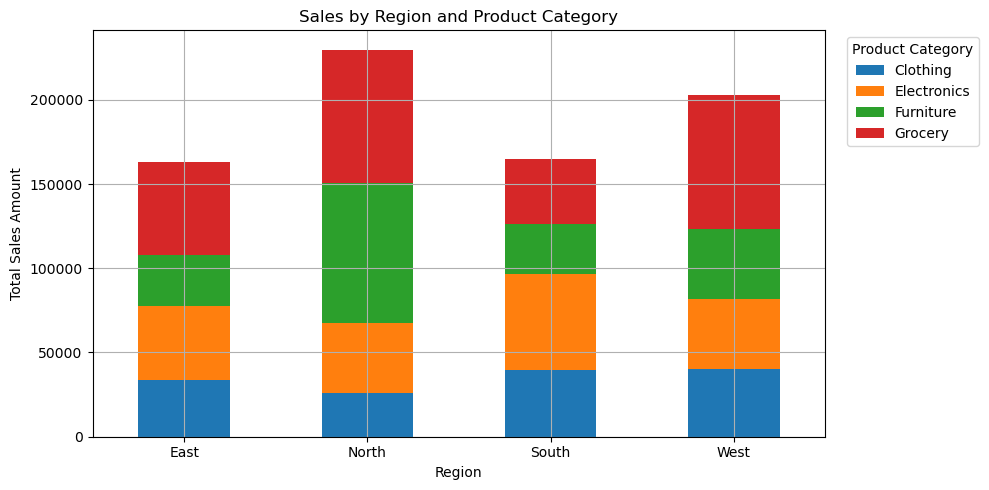

In [9]:
if region_col and category_col and sales_col:
    plt.figure()
    region_category_sales.plot(kind="bar", stacked=True, figsize=(10, 5))
    plt.title("Sales by Region and Product Category")
    plt.xlabel("Region")
    plt.ylabel("Total Sales Amount")
    plt.xticks(rotation=0)
    plt.legend(title="Product Category", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

<Figure size 1000x500 with 0 Axes>

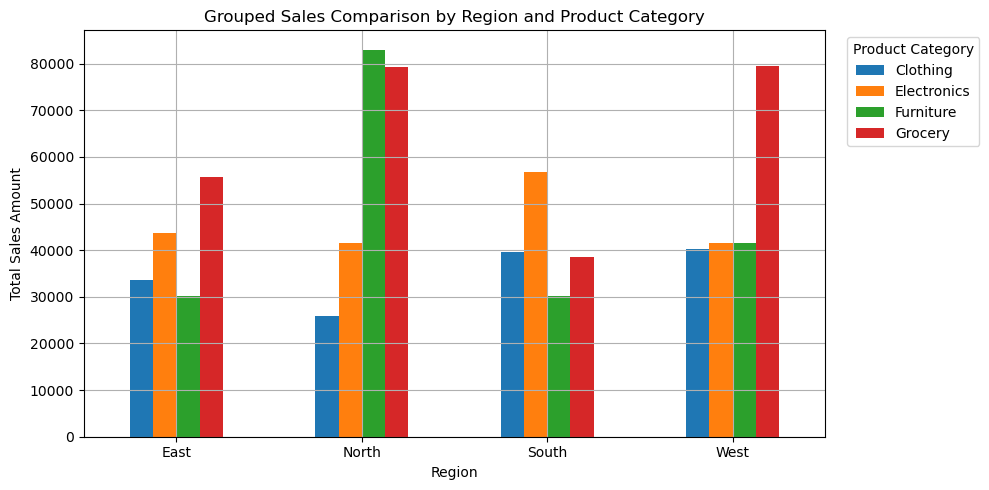

In [10]:
if region_col and category_col and sales_col:
    plt.figure()
    region_category_sales.plot(kind="bar", stacked=False, figsize=(10, 5))
    plt.title("Grouped Sales Comparison by Region and Product Category")
    plt.xlabel("Region")
    plt.ylabel("Total Sales Amount")
    plt.xticks(rotation=0)
    plt.legend(title="Product Category", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()